In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd
from scipy.interpolate import interp1d
from matplotlib.patches import Ellipse

/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [8]:
import subprocess

# === CONFIGURATION ===
file_path = '../Code/system_parameters/system_parameters_CenA.f90'        # path to your Fortran file
line_to_find = '   real(dp) :: a_inj = 0.7d0                    !Power law exponent for dLe_dz(z) ~ z**(-(1 + a_inj)),'  # text in line to search for
new_line = '   real(dp) :: a_inj = 0.6d0                    !Power law exponent for dLe_dz(z) ~ z**(-(1 + a_inj)),\n'  # new content

# === STEP 1: Read and modify the file ===
with open(file_path, 'r') as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if line_to_find in line:
        print(f"Old line: {lines[i].strip()}")
        lines[i] = new_line
        print(f"New line: {lines[i].strip()}")
        break
else:
    raise ValueError(f"Line containing '{line_to_find}' not found.")

# === STEP 2: Write changes back to the file ===
with open(file_path, 'w') as file:
    file.writelines(lines)

! cd ../Code && make clean && make
! cd ../Code && ./run.x

Old line: real(dp) :: a_inj = 0.7d0                    !Power law exponent for dLe_dz(z) ~ z**(-(1 + a_inj)),
New line: real(dp) :: a_inj = 0.6d0                    !Power law exponent for dLe_dz(z) ~ z**(-(1 + a_inj)),
rm -f *.x *.o *.mod *.dat *.bin *.log *~
rm -rf ./test
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  constants.f90


gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  controls.f90
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  system_parameters.f90
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  globals.f90
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  losses.f90
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  mathematics.f90
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops  edistribution.f90
gfortran -fopenmp -c -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=nativ

# Constantes

In [77]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

In [78]:
M_BH = 5.5e7 #             !Black hole mass [Msun]
R_g = 1.477e5*M_BH

h = 6.6260755e-27
k_B = 1.380658e-16
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21  #Kpc a cm
distance = 3.8e3  #Distancia al objeto en kpc
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

# Funciones utiles

In [79]:
def safe_log(x):
    return np.where(x > 0, np.log(x), -300)

In [80]:
def get_j_alpha(nu, delta, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
    
    # Find the energy associated with the given frequency nu
    energy_nu = h * nu * 1e9  # Convert frequency to energy
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["energy"] - energy_nu/delta[z-1])).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["energy", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

In [81]:
def get_z_rz(filename='./../Code/quant_FF.dat',filename2='./../Code/quant_FF_norm.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 5), unpack=True)

In [82]:
def crossed_length(x, R_in, R_out):
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

In [83]:
def Omega_beam(theta1, theta2):
    '''Beam solid angle in terms of the theta_HPBW (theta1 x theta2)
    Use the equation here: https://science.nrao.edu/facilities/vla/proposing/TBconv'''
    return np.pi * theta1 * theta2 / (4 * np.log(2))

def brightness_temperature(I, nu_hz):
    """
    Calculate the brightness temperature for a given intensity and frequency.

    Parameters:
    I (float or numpy.ndarray): Specific intensity [erg/s/cm^2/Hz].
    nu (float): Frequency [Hz].

    Returns:
    float or numpy.ndarray: Brightness temperature [K].
    """
    nu_hz *= 1e9 # Convert GHz to Hz
    

    return I/Omega_beam(0.0168*1e-3,0.0259*1e-3)#(c**2 * I) / (2 * k_B * nu_hz**2*Omega_beam(np.deg2rad(23 * 1e-3 / 3600),np.deg2rad(45 * 1e-3 / 3600))) #[K]

In [84]:
#Esta interpola las funciones de z
def Intensity_import_interp(x_value, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        delta_obs = np.sqrt(delta_obs)
        j, alpha = get_j_alpha(nu, delta_obs)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, j, alpha = Intensity_import_interp._cached_data
    j=j.to_numpy()
    alpha=alpha.to_numpy()
    # Precompute constants

    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(safe_log(z2), safe_log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(safe_log(z2), safe_log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(safe_log(z), safe_log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')

    # Compute intensity
    intensity_result = np.zeros(len(x_value))
    r_avg=0.5*(np.exp(r_out_interp(safe_log(z_value)))+np.exp(r_in_interp(safe_log(z_value))))
    tau_avg=crossed_length(r_avg, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
    for j, x in enumerate(x_value):
        tau = crossed_length(x, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
        intensity_result[j] = np.exp(I_z(safe_log(z_value))) * (-np.expm1(-tau)) #(1+tau)# opt thin #[erg/cm^2/s/erg/sr]
    

    return intensity_result*h, tau_avg #[erg/cm^2/s/Hz/sr]



# Graficos

In [85]:
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
#x = np.linspace(-r_out.max(), r_out.max(), 200)
# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
I = np.zeros((len(z), len(x)))
tau_avg= np.zeros(len(z))
for i, z_value in enumerate(z):
    I[i], tau_avg[i]=Intensity_import_interp(x, 230.0, z_value) #[erg/cm^2/s/Hz/sr]

/tmp/ipykernel_20269/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_20269/1768712390.py:23: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [86]:
if hasattr(Intensity_import_interp, "_cached_data"):
    del Intensity_import_interp._cached_data

In [87]:
def Convolve_map( x_map, y_map, F_map, sigma_x, sigma_y ):    
    # The number of points in the convolved map depends on the beam size and the size of the original map.

    print(len(x_map),x_map.min(),x_map.max())
    # Extremes of the convolved map
    #Modificar esto
    y_min_c = y_map[0] - 5. * sigma_y # 5 beams to the left of the jet base
    y_max_c = y_map[-1] + 5. * sigma_y # 5 beams to the right of the jet end point
    x_min_c = x_map[0] - 4. * sigma_x # 3 beams above the jet lateral end point
    x_max_c = x_map[-1] + 4. * sigma_x # 3 beams below the jet lateral end point
    # Size of the convolved map
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c 
    
    print(F_map.max())
    print(ancho_x, ancho_y)
    # Size of each cell of the convolved map
    Dx_c = f_Ny*sigma_x
    Dy_c = f_Ny*sigma_y

    Dx_c_rad = np.deg2rad(Dx_c * 1e-3 / 3600)
    Dy_c_rad = np.deg2rad(Dy_c * 1e-3 / 3600)

    F_map *= Dx_c_rad*Dy_c_rad
    # Number of cells of the convolved map
    Nx_c = int(ancho_x/Dx_c)
    Ny_c = int(ancho_y/Dy_c)
    print('Numero de celdas del mapa convolucionado:')
    print(Nx_c, Ny_c)

    # Position of the cells of the convolved map
    print(y_min_c)
    x_c = np.linspace( x_min_c, x_max_c, Nx_c)
    y_c = np.linspace( y_min_c, y_max_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    
    F_map_c = np.ones((Nx_c, Ny_c))

    w_x = 0.5/sigma_x**2 # weight for x distance
    w_y = 0.5/sigma_y**2 # weight for y distance

    x_double = np.ones_like(F_map)
    y_double = np.ones_like(F_map)
    for j in range(len(y_map)):
        x_double[:, j] = x_map
    for i in range(len(x_map)):
        y_double[i, :] = y_map

    for i in range(Nx_c):
        for j in range(Ny_c):
            # Gaussian: (1/(2pi*sigma_x*sigma_y)) * exp(-((x-x_c)²/2.sigma_x² + (y-y_c)²/2.sigma_y²))
            gaussian = np.exp(-(np.square(x_double-x_c[i])*w_x + np.square(y_double-y_c[j])*w_y))
            F_map_c[i, j] = np.sum(F_map*gaussian)
            
    S_pre = np.sum(F_map)
    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    # Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
    A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
    A_cell = Dx_c * Dy_c              # cell sample size
    mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
    S_post = np.sum(F_map_c) * mJy_beam
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post/S_pre) )
    
    return x_c, y_c, F_map_c

In [88]:
FWHM_x, FWHM_y= 0.0168, 0.0259 #FWHM in mas
sigma_x, sigma_y =FWHM_x/(2*np.sqrt(2*np.log(2))), FWHM_y/(2*np.sqrt(2*np.log(2))) 
X_c, Y_c, I_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I.T*1e26, sigma_x, sigma_y)

200 -0.06517170291148543 0.06517170291148543
1.0459477428616712e+22
0.18741783080232574 1.1454239285829346
Numero de celdas del mapa convolucionado:
175 694
-0.028443926172607433
Dimension of the convolution grid: 175x694
Pre-conv: S(GHz) = 153.93155504473893 mJy
Post-conv: S(GHz) = 152.6543162339815 mJy
post/pre = 0.9917025537071575


In [89]:
print(I_c.shape)

(175, 694)


In [90]:
T_brillo=brightness_temperature(I_c, 230.0)
T_b=T_brillo


In [91]:
obs_data = pd.read_csv('./EHT_OBS(TBvZ).csv')
obs_z = obs_data.iloc[:, 0].to_numpy()
obs_TB = obs_data.iloc[:, 1].to_numpy()
obs_data2 = pd.read_csv('./EHT_OBS(TBvZ)2.csv')
obs_z2 = obs_data2.iloc[:, 0].to_numpy()
obs_TB2 = obs_data2.iloc[:, 1].to_numpy()

# Take the highest value along the X_c axis for each Y_c (i.e., max over rows)
T_b_df = pd.DataFrame(T_b/1e9, index=X_c, columns=Y_c)
T_b_df_plus=T_b_df[T_b_df.index > 0] #Promedio con valores de x positivos
T_b_df_minus=T_b_df[T_b_df.index < 0] #Promedio con valores de x positivos
# T_b_mean_values = T_b_df_plus.mean(axis=0)
# T_b_mean_values_minus = T_b_df_minus.mean(axis=0)
T_b_mean_values = T_b_df_plus.max(axis=0)
T_b_mean_values_minus = T_b_df_minus.max(axis=0)

# El Grafico

/tmp/ipykernel_20269/1421049207.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(tick_labels)
/tmp/ipykernel_20269/1421049207.py:68: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2].legend()


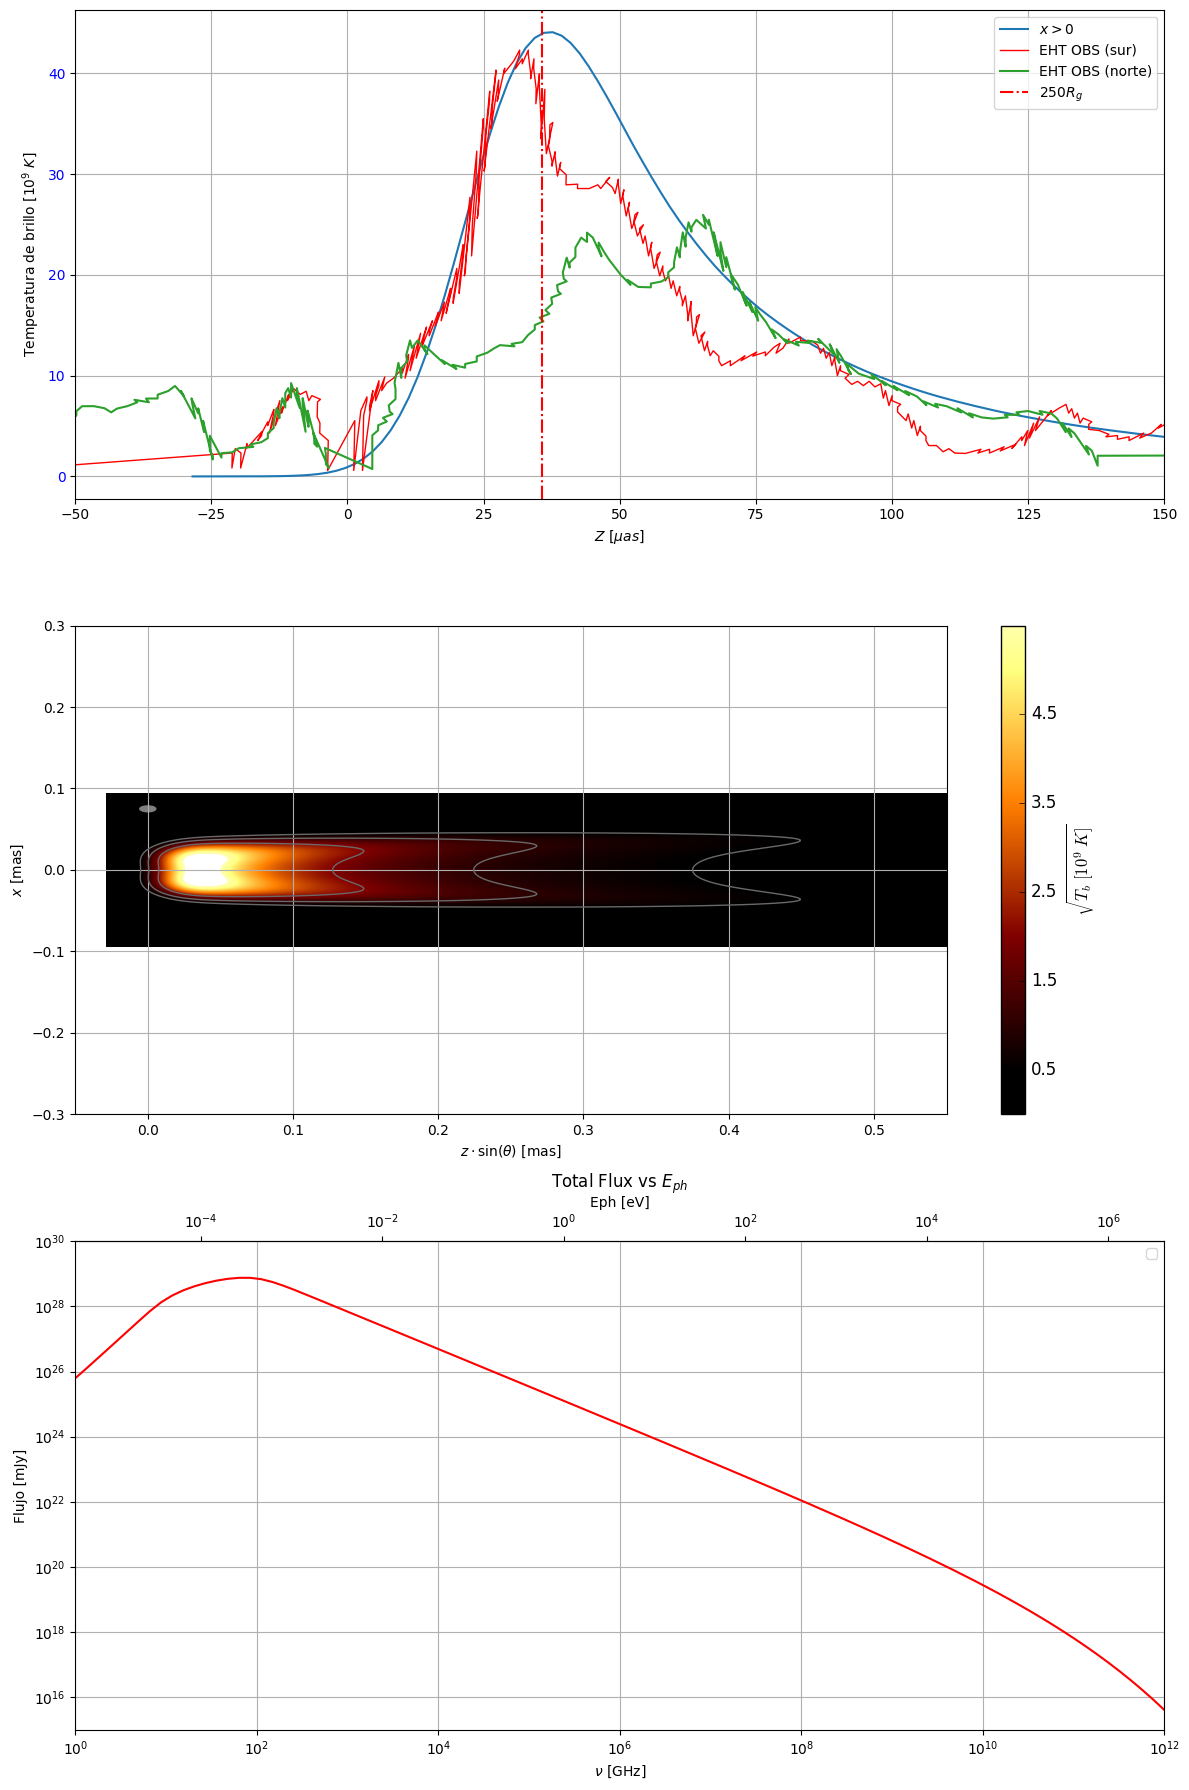

In [75]:
fig, axs = plt.subplots(3, 1, figsize=(12, 18))

# --- T_B vs Z ---
axs[0].plot(Y_c*1e3, T_b_mean_values, label='$x>0$')
#axs[0].plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
axs[0].plot(obs_z, obs_TB, color='red', label='EHT OBS (sur)', lw=1)
axs[0].plot(obs_z2, -obs_TB2, color='C2', label='EHT OBS (norte)')
axs[0].axvline(x=250*R_g*convert*1e3, color='red', linestyle='-.', label='$250R_g$')
axs[0].set_xlabel(fr'$Z~[\mu as]$')
axs[0].set_ylabel(r'Temperatura de brillo $[10^9~K]$')
axs[0].set_xlim(-50, 150)
axs[0].legend()
axs[0].grid()

# Set y-ticks to absolute values and color positive as blue, negative as orange
y_ticks = axs[0].get_yticks()
tick_labels = []
tick_colors = []
for y in y_ticks:
    tick_labels.append(f"{abs(y):.0f}")
    if y >= 0:
        tick_colors.append('blue')
    else:
        tick_colors.append('orange')
axs[0].set_yticklabels(tick_labels)
for tick_label, color in zip(axs[0].get_yticklabels(), tick_colors):
    tick_label.set_color(color)

# --- Mapa de exposicion ---
with plt.style.context(('classic')):
    palette = plt.cm.afmhot
    ticks = [0.5,1.5,2.5,3.5, 4.5]
    norm = matplotlib.colors.Normalize(vmin=0.5, vmax=6.5)
    CS_conv = axs[1].contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,5.5 , 700))
    obs_cont = np.array([-1,-0.5,0,0.5,1,2])
    plot_cont = axs[1].contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])
    el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    axs[1].add_patch(el)
    axs[1].set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    axs[1].set_ylabel(r"$x~{\rm [mas]}$")
    axs[1].set_xlim([-0.05, 0.55])
    axs[1].set_ylim([-0.3, 0.3])
    axs[1].grid()
    fig.colorbar(CS_conv, ax=axs[1], ticks=ticks, label=r'$\sqrt{T_b~[10^9~K]}$')

# --- SED ---
# Read the data from Flux.dat
df_flux9 = pd.read_csv('./../Code/Flux.dat', sep='\s+', header=0)

def energy_to_freq(E_eV):
    h = 4.135667696e-15  # eV·s
    return E_eV / h/1e9

def freq_to_energy(nu):
    h = 4.135667696e-15  # eV·s
    return nu * h*1e9

axs[2].plot(energy_to_freq(df_flux9['Eph/eV']), df_flux9['Flujo_Tot']*1e26 , label=r'', linestyle='-', color='red')
ax_top = axs[2].secondary_xaxis('top', functions=(freq_to_energy, energy_to_freq))
axs[2].set_xlabel(r'$\nu$ [GHz]')
axs[2].set_xscale('log')
axs[2].set_yscale('log')
ax_top.set_xlabel('Eph [eV]')
axs[2].set_ylabel('Flujo [mJy]')
axs[2].set_title('Total Flux vs $E_{ph}$')
axs[2].set_ylim(1e15, 1e30)
axs[2].set_xlim(1,1e12)
axs[2].legend()
axs[2].grid()

plt.tight_layout()
plt.show()
